In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/digit-recognizer/sample_submission.csv
/kaggle/input/competitions/digit-recognizer/train.csv
/kaggle/input/competitions/digit-recognizer/test.csv


In [2]:
df=pd.read_csv('/kaggle/input/competitions/digit-recognizer/train.csv')

In [3]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
df.shape

(42000, 785)

In [12]:
df.sample

<bound method NDFrame.sample of        label  pixel0  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  \
0          1       0       0       0       0       0       0       0       0   
1          0       0       0       0       0       0       0       0       0   
2          1       0       0       0       0       0       0       0       0   
3          4       0       0       0       0       0       0       0       0   
4          0       0       0       0       0       0       0       0       0   
...      ...     ...     ...     ...     ...     ...     ...     ...     ...   
41995      0       0       0       0       0       0       0       0       0   
41996      1       0       0       0       0       0       0       0       0   
41997      7       0       0       0       0       0       0       0       0   
41998      6       0       0       0       0       0       0       0       0   
41999      9       0       0       0       0       0       0       0       0   

       

In [10]:
import matplotlib.pyplot as plt

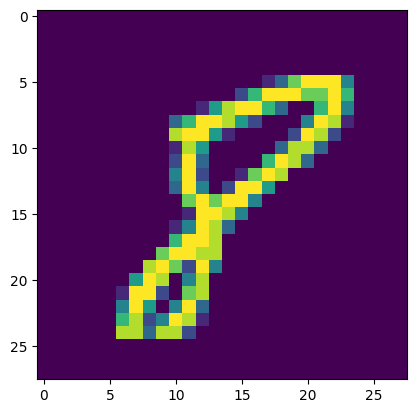

In [11]:
plt.imshow(df.iloc[18306,1:].values.reshape(28,28))

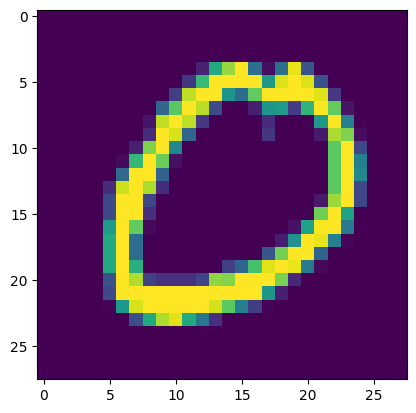

In [13]:
plt.imshow(df.iloc[13051,1:].values.reshape(28,28))

In [15]:
X=df.iloc[:,1:]
y=df.iloc[:,0]

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [18]:
X_train.shape

(33600, 784)

In [20]:
from sklearn.neighbors import KNeighborsClassifier

In [22]:
knn=KNeighborsClassifier()

In [23]:
knn.fit(X_train,y_train)

KNeighborsClassifier()

In [25]:
import time
start=time.time()
y_pred=knn.predict(X_test)
print(time.time()-start)

11.493359565734863


In [26]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9648809523809524

In [29]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [31]:
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [75]:
# from sklearn.decomposition import PCA
# pca=PCA(n_components=200)

In [46]:
X_train=pca.fit_transform(X_train)
X_test=pca.transform(X_test)

In [47]:
X_train.shape

(33600, 200)

In [48]:
knn=KNeighborsClassifier()

In [49]:
X_train_trf=pca.fit_transform(X_train)
X_test_trf=pca.transform(X_test)

In [50]:
X_train_trf.shape

(33600, 200)

In [52]:
y_pred=knn.predict(X_test_trf)

In [54]:
accuracy_score(y_test,y_pred)

0.9507142857142857

In [56]:
for i in range(1,785):
    pca=PCA(n_components=i)
    X_train_trf=pca.fit_transform(X_train)
    X_test_trf=pca.transform(X_test)
    knn=KNeighborsClassifier()
    knn.fit(X_train_trf,y_train)
    y_pred=knn.predict(X_test_trf)
    print(accuracy_score(y_test,y_pred))

0.2580952380952381
0.3236904761904762
0.5104761904761905
0.6663095238095238
0.7378571428571429
0.8227380952380953
0.8436904761904762
0.8721428571428571
0.886547619047619
0.9055952380952381
0.9116666666666666
0.9184523809523809
0.9276190476190476
0.9351190476190476
0.9384523809523809
0.9379761904761905
0.9407142857142857
0.94
0.9425
0.9442857142857143
0.9438095238095238
0.9441666666666667
0.9442857142857143
0.9457142857142857
0.9484523809523809
0.9479761904761905
0.9478571428571428
0.9471428571428572
0.949047619047619
0.9491666666666667
0.9507142857142857
0.9513095238095238
0.95
0.9504761904761905
0.950952380952381
0.9519047619047619
0.9517857142857142
0.9527380952380953
0.9533333333333334
0.9528571428571428
0.9522619047619048
0.9522619047619048
0.9523809523809523
0.9533333333333334
0.9528571428571428
0.9530952380952381
0.9530952380952381
0.9533333333333334
0.9527380952380953
0.9533333333333334
0.9545238095238096
0.954047619047619
0.9541666666666667
0.9541666666666667
0.9546428571428571

ValueError: n_components=201 must be between 0 and min(n_samples, n_features)=200 with svd_solver='covariance_eigh'

In [57]:
#2D coordinate system
pca=PCA(n_components=2)
X_train_trf=pca.fit_transform(X_train)
X_test_trf=pca.transform(X_test)

In [58]:
X_train_trf

array([[-2.71863253, -0.48982409],
       [-0.67698015, -6.75362491],
       [-3.03323281,  6.50981624],
       ...,
       [ 2.14883643,  0.78079444],
       [ 1.05957006,  0.94767312],
       [17.70258446,  1.96188185]])

In [62]:
import plotly.express as px

# Convert target to string so Plotly treats it as a categorical color legend
y_train_trf = y_train.astype(str)

fig = px.scatter(
    x=X_train_trf[:, 0],  # First feature
    y=X_train_trf[:, 1],  # Second feature (Fix: slice the second column)
    color=y_train_trf,
    color_discrete_sequence=px.colors.qualitative.G10,
    labels={'x': 'First Principal Component / Feature 1', 'y': 'Second Principal Component / Feature 2'}
)

fig.show()


In [63]:
#3D coordinate system
pca=PCA(n_components=3)
X_train_trf=pca.fit_transform(X_train)
X_test_trf=pca.transform(X_test)

In [64]:
X_train_trf

array([[-2.71863253, -0.48982409,  1.1354966 ],
       [-0.67698015, -6.75362491, -2.33590139],
       [-3.03323281,  6.50981624,  7.49182983],
       ...,
       [ 2.14883643,  0.78079444, -0.74738774],
       [ 1.05957006,  0.94767312,  3.94973114],
       [17.70258446,  1.96188185, -4.94352837]])

In [65]:

# Convert target to string so Plotly treats it as a categorical color legend
y_train_trf = y_train.astype(str)

fig = px.scatter_3d(
    x=X_train_trf[:, 0],  # Feature 1
    y=X_train_trf[:, 1],  # Feature 2
    z=X_train_trf[:, 2],  # Feature 3
    color=y_train_trf,
    color_discrete_sequence=px.colors.qualitative.G10,
    labels={
        'x': 'Feature 1', 
        'y': 'Feature 2', 
        'z': 'Feature 3'
    }
)

fig.show()


In [66]:
#Eigen Values
pca.explained_variance_

array([40.67111198, 29.17023401, 26.74459621])

In [69]:
pca.components_.shape
#Eigen Vectors

(3, 200)

In [72]:
pca.explained_variance_ratio_*100

array([6.57884468, 4.71849501, 4.32613066])

In [76]:
pca=PCA(n_components=None)
X_train_trf=pca.fit_transform(X_train)
X_test_trf=pca.transform(X_test)

In [77]:
pca.explained_variance_.shape

(200,)

In [79]:
pca.components_.shape

(200, 200)

In [80]:
pca.explained_variance_ratio_

array([0.06578845, 0.04718495, 0.04326131, 0.03373195, 0.02935718,
       0.02564334, 0.02243747, 0.02018825, 0.01783849, 0.01633072,
       0.01558236, 0.01395618, 0.01304253, 0.01277092, 0.01203745,
       0.01159852, 0.01089057, 0.01072036, 0.01037671, 0.0101229 ,
       0.00955169, 0.00932565, 0.00893037, 0.00860554, 0.00838404,
       0.00798174, 0.00793665, 0.00763171, 0.00727623, 0.00716811,
       0.00699769, 0.00685028, 0.00663746, 0.00657917, 0.0065085 ,
       0.00621359, 0.00617728, 0.00600631, 0.00583811, 0.00561788,
       0.00554573, 0.005481  , 0.00532436, 0.00522358, 0.00520446,
       0.00510846, 0.00505687, 0.00502114, 0.00494804, 0.00491302,
       0.00479676, 0.00475621, 0.00463966, 0.00457155, 0.00452982,
       0.00448733, 0.00439945, 0.00435765, 0.00428211, 0.00425528,
       0.00414905, 0.004103  , 0.00402435, 0.00395674, 0.0039156 ,
       0.00384298, 0.00380946, 0.00377555, 0.00371725, 0.00364477,
       0.00362508, 0.00354108, 0.00352111, 0.00347787, 0.00345

In [82]:
np.cumsum(pca.explained_variance_ratio_)

array([0.06578845, 0.1129734 , 0.1562347 , 0.18996665, 0.21932383,
       0.24496717, 0.26740464, 0.28759289, 0.30543138, 0.32176211,
       0.33734447, 0.35130065, 0.36434318, 0.3771141 , 0.38915155,
       0.40075007, 0.41164064, 0.422361  , 0.43273771, 0.44286061,
       0.4524123 , 0.46173795, 0.47066832, 0.47927386, 0.4876579 ,
       0.49563964, 0.50357629, 0.511208  , 0.51848424, 0.52565235,
       0.53265004, 0.53950032, 0.54613779, 0.55271696, 0.55922545,
       0.56543904, 0.57161632, 0.57762264, 0.58346075, 0.58907862,
       0.59462436, 0.60010536, 0.60542971, 0.6106533 , 0.61585776,
       0.62096622, 0.62602308, 0.63104423, 0.63599226, 0.64090528,
       0.64570204, 0.65045825, 0.6550979 , 0.65966945, 0.66419927,
       0.6686866 , 0.67308605, 0.6774437 , 0.68172581, 0.68598108,
       0.69013014, 0.69423313, 0.69825748, 0.70221423, 0.70612983,
       0.70997281, 0.71378227, 0.71755783, 0.72127507, 0.72491985,
       0.72854493, 0.73208601, 0.73560712, 0.73908498, 0.74253

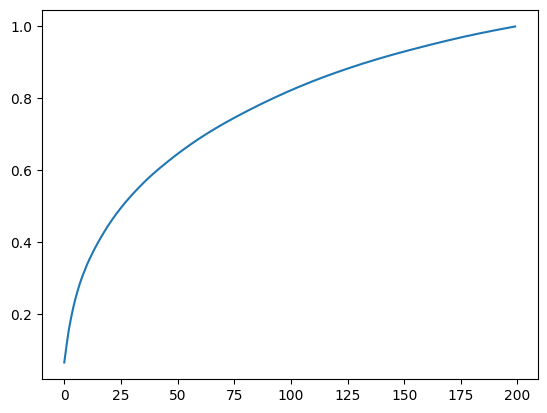

In [83]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))